# Home Credit: My Individual Analytics Portfolio

**Dahyun Kim | Individual capstone work with AI assistance**

This walkthrough explains my work from the business question through model selection and interpretation. I completed the project individually with AI assistance for code, analysis organization, explanations, and writing. The linked working notebooks show the detailed implementation; this separate portfolio narrative explains the decisions and lessons.

**Main result:** The retained gradient booster achieved 0.7573 mean development CV AUC and a recorded 0.74479 Kaggle private AUC. In historical out-of-fold scores, the highest-risk 20% of issued loans contained 51.8% of payment-difficulty cases. This suggests a way to investigate prioritizing review, with substantial false alarms.

## Contents

1. [Business question and my work](#business-question)
2. [Evidence and reproducibility](#evidence)
3. [Why accuracy was insufficient](#imbalance)
4. [Model comparison and selection](#models)
5. [Business value and false alarms](#business-value)
6. [Difficulties, lessons, and next steps](#reflection)
7. [Sources and AI assistance](#sources)

<a id="business-question"></a>
## 1. Business question and my work

Home Credit needs to assess applicants who may have limited conventional credit histories. My analytic objective was to rank the likelihood of the competition's payment-difficulty outcome while explaining the trade-offs of using the score.

My work covered the exploratory investigation, application-level preparation, model comparisons and tuning, and a stakeholder model card. I used application information rather than joining supplementary histories whose feature timing was not sufficiently established. The model's external scores are documented only as normalized external-source scores, so their ingredients and meaning cannot be fully explained from this dataset.

The [working EDA](01_eda.ipynb), [model experiments](02_modeling.ipynb), and [stakeholder model card](04_model_card.ipynb) preserve the detailed project records.

<a id="evidence"></a>
## 2. Evidence and reproducibility

The cells below read committed **aggregate results** extracted from the saved project artifacts. They reproduce calculations and plots, not model training or an independent evaluation. Raw data and row-level predictions are excluded. The JSON records the source hashes; [REPRODUCING.md](../REPRODUCING.md) describes how to regenerate the underlying evidence with the competition data.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Locate the repository from its root or the notebooks directory.
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in candidates if (p / "reports/portfolio/metrics.json").exists())
with (ROOT / "reports/portfolio/metrics.json").open() as stream:
    evidence = json.load(stream)

# These are aggregate historical counts, not applicant-level records.
population = evidence["population"]
n = population["labeled_applications"]
positive = population["difficulty_cases"]
display(pd.DataFrame({"Measure": ["Labeled applications", "Payment-difficulty cases", "Competition test applications"],
                      "Count": [n, positive, population["competition_test_applications"]]}))

Matplotlib is building the font cache; this may take a moment.


,Measure,Count
0,Labeled applications,307511
1,Payment-difficulty cases,24825
2,Competition test applications,48744


<a id="imbalance"></a>
## 3. Why accuracy was insufficient

Only about 8% of labeled applications have the payment-difficulty outcome. A classifier predicting the majority outcome for everyone can appear accurate while identifying none of the difficult cases. This is why the modeling comparison emphasizes ROC-AUC, with threshold and subgroup analyses considered separately.

In [2]:
# Show the accuracy of predicting no difficulty for every application.
difficulty_rate = positive / n
majority_accuracy = 1 - difficulty_rate
display(pd.DataFrame({
    "Measure": ["Observed payment-difficulty rate", "Always-no-difficulty accuracy", "Always-no-difficulty recall"],
    "Value": [f"{difficulty_rate:.2%}", f"{majority_accuracy:.2%}", "0.00%"],
}))

,Measure,Value
0,Observed payment-difficulty rate,8.07%
1,Always-no-difficulty accuracy,91.93%
2,Always-no-difficulty recall,0.00%


**Interpretation:** The majority baseline achieves 91.93% accuracy with zero recall and 0.50 AUC. Accuracy alone would hide the business problem. ROC-AUC measures ranking across cutoffs; it does not determine a profitable decision rule or demonstrate calibrated probabilities.

<a id="models"></a>
## 4. Model comparison and selection

The experiments used identical shuffled three-fold stratified splits with seed 42. Preparation thresholds, missingness choices, imputation, category encoding, and scaling were learned inside the training portion of each fold. IDs were removed from predictors. An index audit checked that validation rows did not enter those fitting steps.

Twenty parameter combinations were searched on a 5,000-row stratified sample, then the selected configuration was compared on the original full-data folds. Because this sample came from the same labeled population, that confirmation is model development rather than fully nested validation.

In [3]:
# Display the recorded model comparison, without fitting any estimator.
comparison = pd.DataFrame(evidence["models"])[["model", "mean_roc_auc", "std_roc_auc"]]
comparison.columns = ["Model", "Mean CV AUC", "Fold SD"]
display(comparison.round(6))

decision = evidence["tuning_decision"]
display(pd.DataFrame({
    "Tuning decision": ["Mean AUC gain", "Predefined minimum gain", "Retained configuration"],
    "Recorded value": [f"{decision['mean_auc_gain']:.6f}",
                       f"{decision['minimum_mean_gain']:.6f}", decision["selected_configuration"]],
}))

,Model,Mean CV AUC,Fold SD
0,Histogram gradient boosting (unweighted),0.757301,0.002343
1,Histogram gradient boosting (balanced),0.757196,0.002134
2,Logistic regression (balanced),0.749993,0.003327
3,Logistic regression (unweighted),0.749777,0.002926
4,Random forest (balanced subsample),0.731238,0.001951
5,Majority-class dummy,0.500000,0.000000


,Tuning decision,Recorded value
0,Mean AUC gain,0.000638
1,Predefined minimum gain,0.001000
2,Retained configuration,default


**Why retain the default model?** The sample-tuned model improved all three folds, but its mean gain of 0.000638 and pooled OOF gain of 0.000646 fell below the predefined 0.001 requirements. I retained the default unweighted histogram booster rather than treating every higher score as sufficient evidence to change the model.

The recorded private Kaggle result provides a separate perspective on generalization. It should not be mixed with CV scores in the model-selection table.

In [4]:
# Keep model-development and competition-held-out scores distinct.
retained = next(m for m in evidence["models"]
                if m["model"] == "Histogram gradient boosting (unweighted)")
scores = evidence["kaggle_scores"]
display(pd.DataFrame({
    "Evaluation": ["Mean development CV", "Kaggle public (recorded)", "Kaggle private (recorded)"],
    "ROC-AUC": [retained["mean_roc_auc"], scores["public_auc"], scores["private_auc"]],
}).round(6))
print(f"Mean development CV minus private Kaggle AUC: {retained['mean_roc_auc'] - scores['private_auc']:.6f}")

,Evaluation,ROC-AUC
0,Mean development CV,0.757301
1,Kaggle public (recorded),0.745310
2,Kaggle private (recorded),0.744790


Mean development CV minus private Kaggle AUC: 0.012511


**Interpretation:** Private AUC is about 0.0125 below local mean CV AUC. The local estimate was optimistic relative to this competition partition. Sampling, development selection, or train/test distribution differences may contribute; this comparison does not identify the cause. The project did not reach its proposed 0.78 AUC target.

<a id="business-value"></a>
## 5. Business value and false alarms

A lender has limited capacity to investigate applications. To connect ranking quality to that constraint, I summarize how many observed difficult cases fall into the highest-scored 20% of historical issued loans. The volume is an illustrative classroom scenario, not an optimized review capacity or a validated lending policy. Counts come from saved predictions where each row was held out during its fold's fit.

,Measure,Value
0,Historical loans in the highest-risk group,"61,502"
1,Difficult cases in that group,"12,868"
2,Share of all difficult cases captured,51.83%
3,No recorded difficulty within that group,79.08%


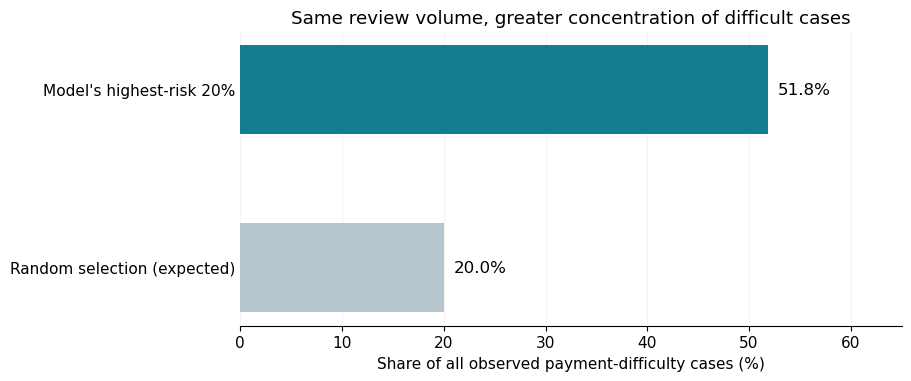

In [5]:
risk = evidence["risk_concentration"]
reviewed = risk["selected_rows"]
captured = risk["selected_difficulty_cases"]
capture_rate = captured / positive
false_alarm_share = (reviewed - captured) / reviewed

# Compare concentration with the expected share under random selection.
# This expectation is not a result from an actually drawn random sample.
random_capture = reviewed / n
display(pd.DataFrame({
    "Measure": ["Historical loans in the highest-risk group", "Difficult cases in that group",
                "Share of all difficult cases captured", "No recorded difficulty within that group"],
    "Value": [f"{reviewed:,}", f"{captured:,}", f"{capture_rate:.2%}", f"{false_alarm_share:.2%}"],
}))

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
fig, ax = plt.subplots(figsize=(9, 3.7), layout="constrained")
values = [100 * random_capture, 100 * capture_rate]
bars = ax.barh(["Random selection (expected)", "Model's highest-risk 20%"], values,
               color=["#B7C6CE", "#147D92"], height=.5)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in values], padding=7, fontsize=12)
ax.set(xlim=(0, 65), xlabel="Share of all observed payment-difficulty cases (%)",
       title="Same review volume, greater concentration of difficult cases")
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", alpha=.15)
ax.set_axisbelow(True)
fig.savefig(ROOT / "reports/portfolio/figures/risk_concentration.png", dpi=180,
            bbox_inches="tight", facecolor="white")
plt.show()

**Interpretation:** The highest-risk 61,502 loans contain 12,868 of the 24,825 difficult cases, or **51.8%**. Random selection at that volume would contain about **20% in expectation**. This supports investigating focused review.

However, **79.1% of the highest-risk group had no recorded difficulty**. A high score is not proof that an applicant will have difficulty, and rejecting the entire group would create many false alarms. The issued-loan dataset does not reveal outcomes for rejected applicants. This analysis does not establish savings, cases prevented, better access, or improvement over Home Credit's current policy.

The model card uses a separate, externally sourced financial-proxy scenario for threshold sensitivity. That cutoff is not used to define this top-20% group. Actual value would require loan-level revenue, exposure, losses, funding and review costs, and a comparison against current decisions.

<a id="reflection"></a>
## 6. Difficulties, lessons, and next steps

| Difficulty | Response in the project | Lesson |
| --- | --- | --- |
| Missing values and impossible employment codes | Preserve raw data, use explicit flags, and recode documented sentinels. | A convenient numeric value can represent a data-quality issue rather than real information. |
| Imbalanced outcomes | Compare AUC and examine threshold trade-offs alongside accuracy. | The metric must reflect the question the business needs answered. |
| Leakage and uncertain feature timing | Fit learned preparation within folds and defer unverified historical joins. | Validation is part of the modeling pipeline, not a step after feature engineering. |
| Tiny tuning gains | Apply a predefined retention rule and keep the default. | More tuning does not guarantee a meaningful improvement. |
| Explaining model use | Document SHAP, sensitive features, simulated selection, and uncertainty. | A model association is not a causal explanation or a validated business decision. |

My main lesson is to separate evidence about ranking, decisions, and value. I can explain why the default model was retained, why high accuracy was misleading, and why concentration alone does not justify rejecting applicants.

Next I would obtain an untouched or deployment-representative evaluation set, assess calibration and subgroup errors with uncertainty, validate alternatives to sensitive and opaque inputs, and compare against current policy using verified economics. Those steps are proposals, not completed outcomes.

<a id="sources"></a>
## 7. Sources and AI assistance

- [Home Credit competition data](https://www.kaggle.com/competitions/home-credit-default-risk/data): dataset and target documentation.
- [Working EDA](01_eda.ipynb), [modeling notebook](02_modeling.ipynb), [model-card calculations](03_model_card_analysis.ipynb), and [stakeholder model card](04_model_card.ipynb): detailed project records.
- [Aggregate evidence](../reports/portfolio/metrics.json): extracted saved-configuration results, recorded leaderboard scores, aggregate OOF counts, and source hashes. These are original development predictions, not a new holdout.
- [Reproduction guide](../REPRODUCING.md): environment, data placement, and execution order.

AI assistance contributed to code, analysis structure, interpretations, and writing throughout this individual project. These outputs should be understood as an AI-assisted workflow. This walkthrough reproduces aggregate arithmetic and visualizations; it does not claim a fresh training run, independent validation, realized financial returns, or production deployment.